# Análisis comparativo: Sistema LLM+MCP vs. Rspamd

Compara, correo por correo, el orquestador LLM+MCP contra Rspamd sobre el mismo conjunto de
evaluación externo (`experiments/external_eval/eval_external.csv`: 500 phishing de Phishing Pot +
500 legítimos de TREC 2007).

**Entradas**
- Resultados del sistema LLM+MCP: `results_raw.jsonl` (generado por `run_evaluation.py` del orquestador).
- Resultados de Rspamd: `experiments/eval_system/rspamd_results_raw.jsonl` (generado por `eval_rspamd_external.py`).

Ambos archivos comparten el mismo schema por correo. Las figuras se guardan en `experiments/figures/`.

## 1. Setup e importaciones

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import binomtest
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 150, "savefig.dpi": 150, "savefig.bbox": "tight"})

# Umbrales de decisión de cada sistema
THRESHOLD_LLM = 0.5      # sobre puntaje_riesgo (0-1)
THRESHOLD_RSPAMD = 6.0   # sobre el score crudo de Rspamd (no normalizado)
RSPAMD_SCORE_TOPE = 20.0 # divisor usado para normalizar el score de Rspamd a [0, 1]

NOMBRE_LLM = "Sistema LLM+MCP"
NOMBRE_RSPAMD = "Rspamd 4.1.5"
COLOR_LLM = "tab:blue"
COLOR_RSPAMD = "tab:orange"

# Carpeta experiments/ (funciona si el notebook se ejecuta desde experiments/ o desde la raíz del repo)
BASE = Path.cwd() if (Path.cwd() / "eval_system").exists() else Path.cwd() / "experiments"

# Los resultados del LLM pueden estar en experiments/data/ o en data/ (raíz del repo)
RUTAS_LLM = [BASE / "data" / "results_raw.jsonl", BASE.parent / "data" / "results_raw.jsonl"]
RUTA_LLM = next((p for p in RUTAS_LLM if p.exists()), None)
RUTA_RSPAMD = BASE / "eval_system" / "rspamd_results_raw.jsonl"
assert RUTA_LLM is not None, f"No se encontró results_raw.jsonl en: {[str(p) for p in RUTAS_LLM]}"
assert RUTA_RSPAMD.exists(), f"No se encontró {RUTA_RSPAMD}"

FIGURES_DIR = BASE / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Resultados LLM+MCP:", RUTA_LLM)
print("Resultados Rspamd: ", RUTA_RSPAMD)
print("Figuras en:        ", FIGURES_DIR)

Resultados LLM+MCP: C:\Users\50250\Desktop\Sofía Mishell Velásquez UVG\Quinto año\Segundo Semestre\Tesis\Trabajo-de-Graduacion\data\results_raw.jsonl
Resultados Rspamd:  C:\Users\50250\Desktop\Sofía Mishell Velásquez UVG\Quinto año\Segundo Semestre\Tesis\Trabajo-de-Graduacion\experiments\eval_system\rspamd_results_raw.jsonl
Figuras en:         C:\Users\50250\Desktop\Sofía Mishell Velásquez UVG\Quinto año\Segundo Semestre\Tesis\Trabajo-de-Graduacion\experiments\figures


In [2]:
FUENTES = {"phishing_pot": "Phishing Pot", "trec_2007": "TREC 2007"}


def cargar_jsonl(ruta: Path) -> pd.DataFrame:
    with ruta.open(encoding="utf-8") as f:
        df = pd.DataFrame([json.loads(linea) for linea in f if linea.strip()])
    # clasificacion es "phishing"/"legitimo" (o nulo si hubo error) -> 1/0
    df["pred"] = df["clasificacion"].map({"phishing": 1, "legitimo": 0})
    df["con_error"] = df["error"].notna()
    return df


df_llm = cargar_jsonl(RUTA_LLM)
df_rspamd = cargar_jsonl(RUTA_RSPAMD)

# Merge por id para el análisis emparejado
columnas = ["id", "label_real", "pred", "puntaje_riesgo", "con_error"]
df = df_llm[columnas + ["arquetipo_id"]].merge(
    df_rspamd[columnas + ["rspamd_score", "rspamd_action"]],
    on="id", how="outer", suffixes=("_llm", "_rspamd"), validate="one_to_one",
)
df["label_real"] = df["label_real_llm"].fillna(df["label_real_rspamd"]).astype(int)

# La fuente no viene en los JSONL; se deriva del prefijo del id (phishing_pot_* / trec_2007_*)
df["source"] = df["id"].str.extract(r"^(phishing_pot|trec_2007)", expand=False).map(FUENTES).fillna("Otro")

print(f"LLM+MCP: {len(df_llm)} filas | Rspamd: {len(df_rspamd)} filas | merge: {len(df)} filas")
df.head()

LLM+MCP: 1000 filas | Rspamd: 1000 filas | merge: 1000 filas


,id,label_real_llm,pred_llm,puntaje_riesgo_llm,con_error_llm,arquetipo_id,label_real_rspamd,pred_rspamd,puntaje_riesgo_rspamd,con_error_rspamd,rspamd_score,rspamd_action,label_real,source
0,phishing_pot_sample-1,1,1,0.72,False,0.0,1,1,0.4650,False,9.30,add header,1,Phishing Pot
1,phishing_pot_sample-10,1,1,0.92,False,13.0,1,1,0.4100,False,8.20,add header,1,Phishing Pot
2,phishing_pot_sample-100,1,0,0.15,False,0.0,1,0,0.2625,False,5.25,greylist,1,Phishing Pot
3,phishing_pot_sample-1000,1,1,0.78,False,0.0,1,1,0.3375,False,6.75,add header,1,Phishing Pot
4,phishing_pot_sample-1001,1,1,0.92,False,13.0,1,1,0.4100,False,8.20,add header,1,Phishing Pot


## 2. Resumen del dataset

In [3]:
resumen = pd.DataFrame({
    nombre: {
        "Total de correos": len(d),
        "Phishing (label_real = 1)": int((d["label_real"] == 1).sum()),
        "Legítimos (label_real = 0)": int((d["label_real"] == 0).sum()),
        "Con error (error != null)": int(d["con_error"].sum()),
        "Válidos para métricas": int((~d["con_error"] & d["pred"].notna()).sum()),
        "Costo total (USD)": f"{d['costo_usd'].sum():.2f}",
        "Tiempo mediano por correo (s)": f"{d['tiempo_ms'].median() / 1000:.2f}",
    }
    for nombre, d in [(NOMBRE_LLM, df_llm), (NOMBRE_RSPAMD, df_rspamd)]
}).astype(str)
resumen

,Sistema LLM+MCP,Rspamd 4.1.5
Total de correos,1000,1000
Phishing (label_real = 1),500,500
Legítimos (label_real = 0),500,500
Con error (error != null),0,0
Válidos para métricas,1000,1000
Costo total (USD),21.87,0.00
Tiempo mediano por correo (s),22.11,0.27


In [4]:
# Verificación: ambos sistemas evaluaron exactamente los mismos correos, con las mismas etiquetas
ids_llm, ids_rspamd = set(df_llm["id"]), set(df_rspamd["id"])
print(f"IDs solo en LLM+MCP: {len(ids_llm - ids_rspamd)} | solo en Rspamd: {len(ids_rspamd - ids_llm)} | en ambos: {len(ids_llm & ids_rspamd)}")
assert ids_llm == ids_rspamd, "Los dos sistemas no evaluaron el mismo conjunto de correos"
assert df_llm["id"].is_unique and df_rspamd["id"].is_unique, "Hay ids duplicados"
assert (df["label_real_llm"] == df["label_real_rspamd"]).all(), "label_real difiere entre archivos"

# Los correos con error en cualquiera de los dos sistemas se excluyen de las métricas
validos = ~df["con_error_llm"] & ~df["con_error_rspamd"] & df["pred_llm"].notna() & df["pred_rspamd"].notna()
df_ok = df[validos].copy()
df_ok[["pred_llm", "pred_rspamd"]] = df_ok[["pred_llm", "pred_rspamd"]].astype(int)
print(f"Correos excluidos por error: {int((~validos).sum())} | usados en el análisis: {len(df_ok)}")

# La clasificación de Rspamd debe coincidir con rspamd_score >= THRESHOLD_RSPAMD
assert ((df_ok["rspamd_score"] >= THRESHOLD_RSPAMD).astype(int) == df_ok["pred_rspamd"]).all()

# En el LLM, la clasificación la emite el modelo; puede no coincidir con puntaje_riesgo >= THRESHOLD_LLM
discrepancias = int(((df_ok["puntaje_riesgo_llm"] >= THRESHOLD_LLM).astype(int) != df_ok["pred_llm"]).sum())
print(f"Correos donde la clasificación del LLM no coincide con puntaje_riesgo >= {THRESHOLD_LLM}: {discrepancias} "
      "(se usa el campo clasificacion como predicción)")

df_ok.groupby(["source", "label_real"]).size().rename("n_correos").to_frame()

IDs solo en LLM+MCP: 0 | solo en Rspamd: 0 | en ambos: 1000
Correos excluidos por error: 0 | usados en el análisis: 1000
Correos donde la clasificación del LLM no coincide con puntaje_riesgo >= 0.5: 3 (se usa el campo clasificacion como predicción)


,,n_correos
source,label_real,
Phishing Pot,1,500
TREC 2007,0,500


## 3. Métricas agregadas — tabla comparativa

Las predicciones de cada sistema salen del campo `clasificacion`; el AUC-ROC usa `puntaje_riesgo` como
score continuo. En verde, el mejor valor de cada fila (en FNR y FPR, menor es mejor).

In [5]:
y_true = df_ok["label_real"].to_numpy()


def calcular_metricas(pred, score) -> dict:
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall (Sensitivity)": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "MCC": matthews_corrcoef(y_true, pred),
        "AUC-ROC": roc_auc_score(y_true, score),
        "FNR = FN / (FN + TP)": fn / (fn + tp),
        "FPR = FP / (FP + TN)": fp / (fp + tn),
    }


metricas_llm = calcular_metricas(df_ok["pred_llm"], df_ok["puntaje_riesgo_llm"])
metricas_rspamd = calcular_metricas(df_ok["pred_rspamd"], df_ok["puntaje_riesgo_rspamd"])

# Cobertura de señales de ingeniería social: % de phishing reales con arquetipo asignado (solo LLM)
phishing_reales = df_ok[df_ok["label_real"] == 1]
metricas_llm["Cobertura de señales (arquetipo)"] = phishing_reales["arquetipo_id"].notna().mean()
metricas_rspamd["Cobertura de señales (arquetipo)"] = np.nan  # no aplica

tabla_metricas = pd.DataFrame({NOMBRE_LLM: metricas_llm, NOMBRE_RSPAMD: metricas_rspamd})
tabla_metricas["Diferencia (LLM - Rspamd)"] = tabla_metricas[NOMBRE_LLM] - tabla_metricas[NOMBRE_RSPAMD]

MENOR_ES_MEJOR = {"FNR = FN / (FN + TP)", "FPR = FP / (FP + TN)"}


def resaltar_mejor(fila: pd.Series) -> list[str]:
    estilos = [""] * len(fila)
    valores = fila[[NOMBRE_LLM, NOMBRE_RSPAMD]]
    if valores.isna().any() or valores.iloc[0] == valores.iloc[1]:
        return estilos
    mejor = valores.idxmin() if fila.name in MENOR_ES_MEJOR else valores.idxmax()
    estilos[fila.index.get_loc(mejor)] = "background-color: #b7e4c7; color: black; font-weight: bold"
    return estilos


(tabla_metricas.style
    .apply(resaltar_mejor, axis=1)
    .format("{:.4f}", na_rep="N/A")
    .format("{:+.4f}", subset=["Diferencia (LLM - Rspamd)"], na_rep="N/A")
    .set_caption(f"Métricas sobre {len(df_ok)} correos (verde = mejor valor de la fila)"))

,Sistema LLM+MCP,Rspamd 4.1.5,Diferencia (LLM - Rspamd)
Accuracy,0.9150,0.7850,+0.1300
Precision,0.9601,0.7387,+0.2214
Recall (Sensitivity),0.8660,0.8820,-0.0160
F1,0.9106,0.8040,+0.1066
MCC,0.8340,0.5810,+0.2530
AUC-ROC,0.9748,0.8387,+0.1361
FNR = FN / (FN + TP),0.1340,0.1180,+0.0160
FPR = FP / (FP + TN),0.0360,0.3120,-0.2760
Cobertura de señales (arquetipo),0.9140,N/A,N/A


## 4. Matrices de confusión

Cada celda muestra el número de correos y, entre paréntesis, el porcentaje respecto a su clase real (fila).

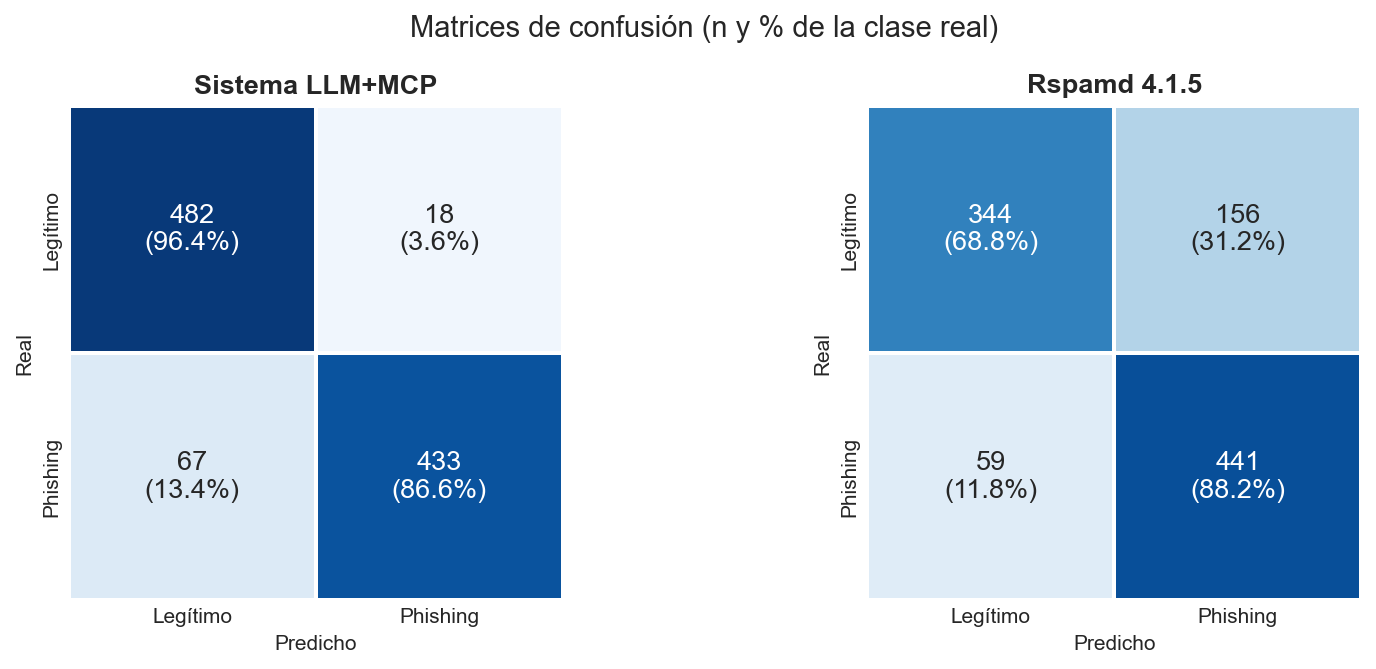

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
etiquetas = ["Legítimo", "Phishing"]

for ax, nombre, col in [(axes[0], NOMBRE_LLM, "pred_llm"), (axes[1], NOMBRE_RSPAMD, "pred_rspamd")]:
    cm = confusion_matrix(y_true, df_ok[col], labels=[0, 1])
    pct = cm / cm.sum(axis=1, keepdims=True) * 100
    anotaciones = np.array([[f"{cm[i, j]}\n({pct[i, j]:.1f}%)" for j in range(2)] for i in range(2)])
    sns.heatmap(cm, annot=anotaciones, fmt="", cmap="Blues", cbar=False, square=True,
                xticklabels=etiquetas, yticklabels=etiquetas, annot_kws={"size": 13},
                vmin=0, vmax=cm.sum(axis=1).max(), linewidths=1, linecolor="white", ax=ax)
    ax.set_title(nombre, fontsize=13, fontweight="bold")
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")

fig.suptitle("Matrices de confusión (n y % de la clase real)", fontsize=14)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "confusion_matrices.png")
plt.show()

## 5. Curvas ROC

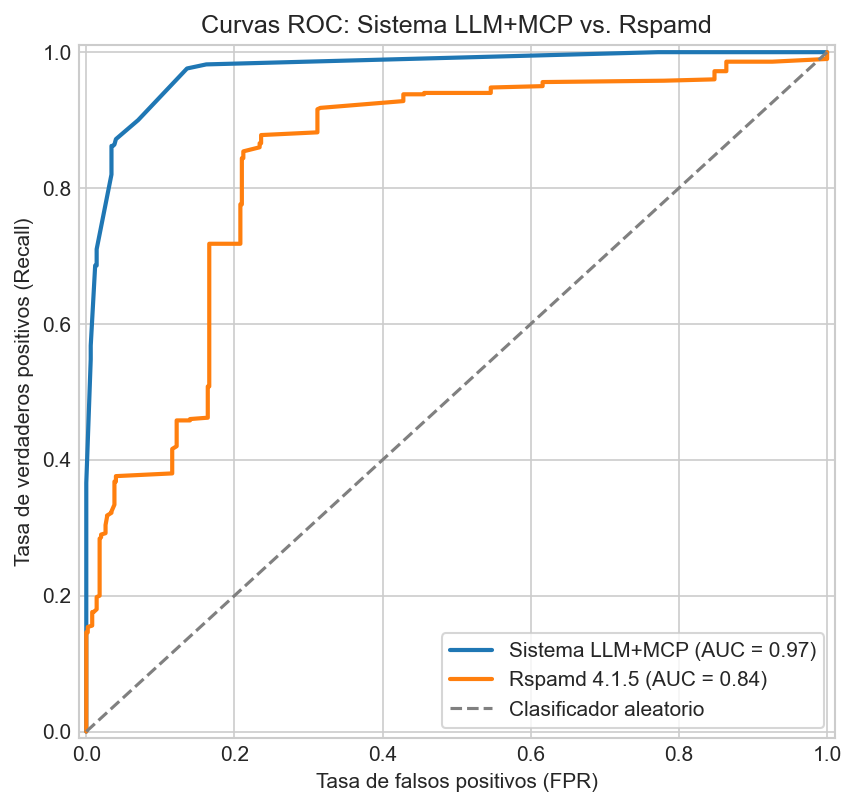

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 6))

for nombre, col, color in [(NOMBRE_LLM, "puntaje_riesgo_llm", COLOR_LLM),
                           (NOMBRE_RSPAMD, "puntaje_riesgo_rspamd", COLOR_RSPAMD)]:
    fpr, tpr, _ = roc_curve(y_true, df_ok[col])
    auc = roc_auc_score(y_true, df_ok[col])
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f"{nombre} (AUC = {auc:.2f})")

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Clasificador aleatorio")
ax.set_xlabel("Tasa de falsos positivos (FPR)")
ax.set_ylabel("Tasa de verdaderos positivos (Recall)")
ax.set_title("Curvas ROC: Sistema LLM+MCP vs. Rspamd")
ax.set_xlim(-0.01, 1.01)
ax.set_ylim(-0.01, 1.01)
ax.legend(loc="lower right", frameon=True)
fig.savefig(FIGURES_DIR / "roc_curves.png")
plt.show()

## 6. Distribución de scores

Histograma de `puntaje_riesgo` por clase real. La línea punteada marca el umbral de decisión:
0.5 para el LLM y 0.3 para Rspamd (6.0 / 20.0, el umbral crudo normalizado).

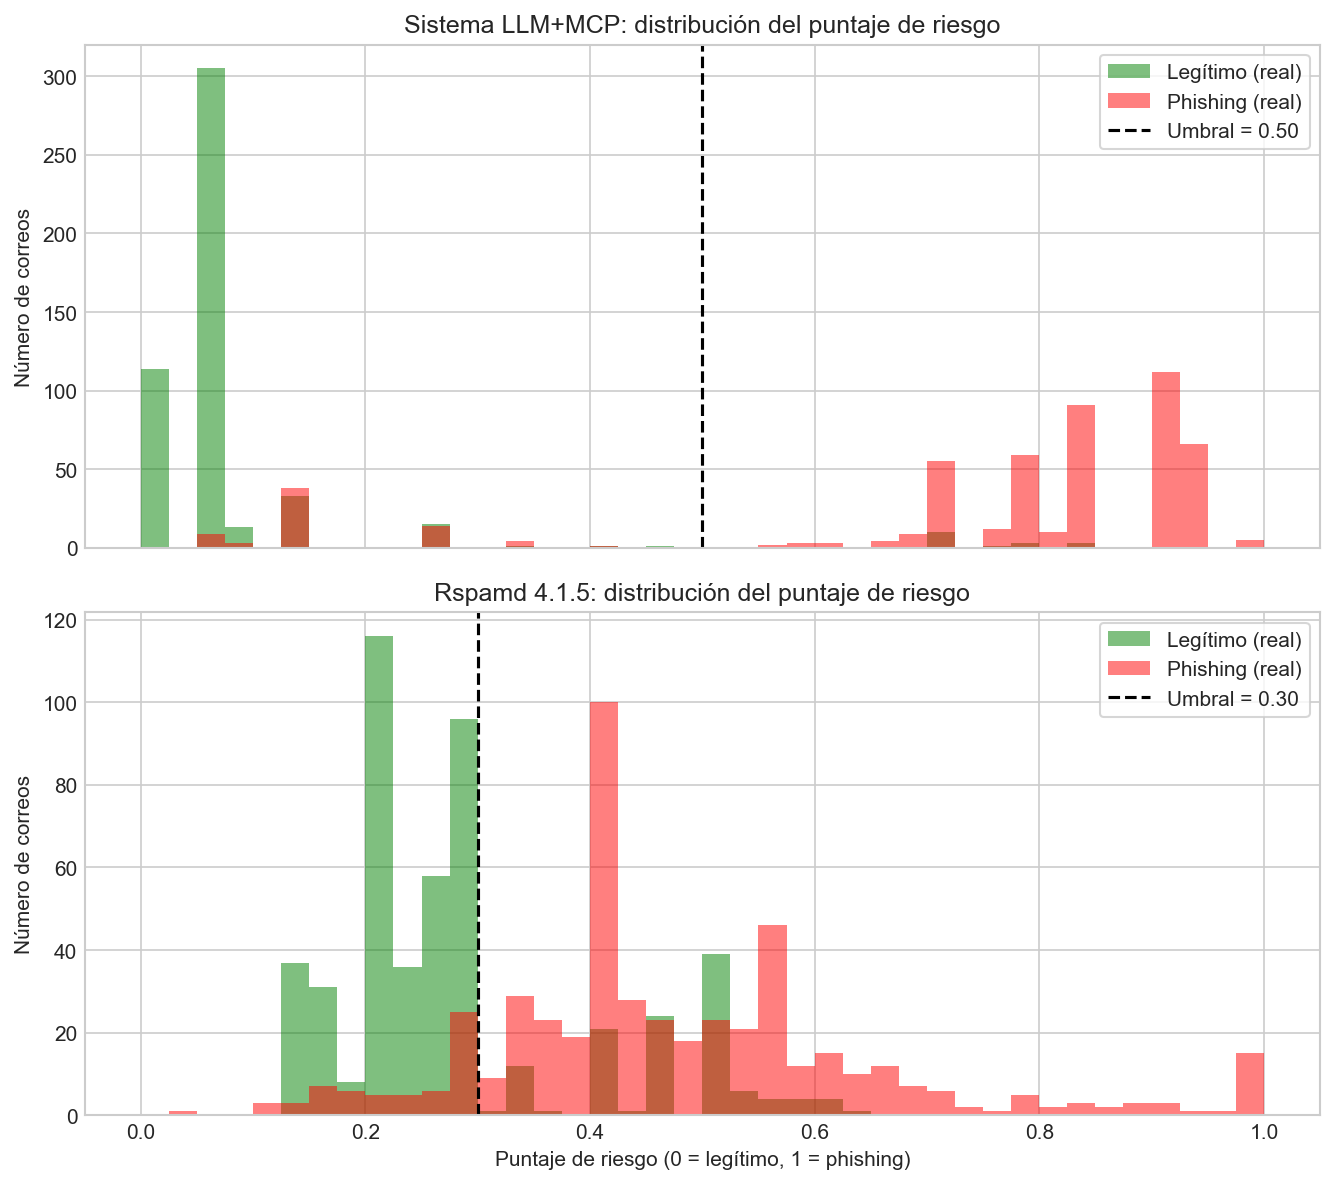

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(9, 8), sharex=True)
bins = np.linspace(0, 1, 41)

for ax, nombre, col, umbral in [
    (axes[0], NOMBRE_LLM, "puntaje_riesgo_llm", THRESHOLD_LLM),
    (axes[1], NOMBRE_RSPAMD, "puntaje_riesgo_rspamd", THRESHOLD_RSPAMD / RSPAMD_SCORE_TOPE),
]:
    ax.hist(df_ok.loc[df_ok["label_real"] == 0, col], bins=bins, color="green", alpha=0.5, label="Legítimo (real)")
    ax.hist(df_ok.loc[df_ok["label_real"] == 1, col], bins=bins, color="red", alpha=0.5, label="Phishing (real)")
    ax.axvline(umbral, linestyle="--", color="black", label=f"Umbral = {umbral:.2f}")
    ax.set_title(f"{nombre}: distribución del puntaje de riesgo")
    ax.set_ylabel("Número de correos")
    ax.legend(frameon=True)

axes[1].set_xlabel("Puntaje de riesgo (0 = legítimo, 1 = phishing)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "score_distributions.png")
plt.show()

## 7. Análisis de errores — casos donde los sistemas difieren

In [9]:
df_ok["acierta_llm"] = df_ok["pred_llm"] == df_ok["label_real"]
df_ok["acierta_rspamd"] = df_ok["pred_rspamd"] == df_ok["label_real"]

CATEGORIAS = ["Ambos correctos", "Solo LLM correcto", "Solo Rspamd correcto", "Ambos incorrectos"]
df_ok["categoria"] = np.select(
    [df_ok["acierta_llm"] & df_ok["acierta_rspamd"],
     df_ok["acierta_llm"] & ~df_ok["acierta_rspamd"],
     ~df_ok["acierta_llm"] & df_ok["acierta_rspamd"]],
    CATEGORIAS[:3], default=CATEGORIAS[3],
)

conteo = df_ok["categoria"].value_counts().reindex(CATEGORIAS, fill_value=0)
tabla_categorias = pd.DataFrame({"Correos": conteo, "% del total": (conteo / len(df_ok) * 100).round(1)})
tabla_categorias

,Correos,% del total
categoria,,
Ambos correctos,717,71.7
Solo LLM correcto,198,19.8
Solo Rspamd correcto,68,6.8
Ambos incorrectos,17,1.7


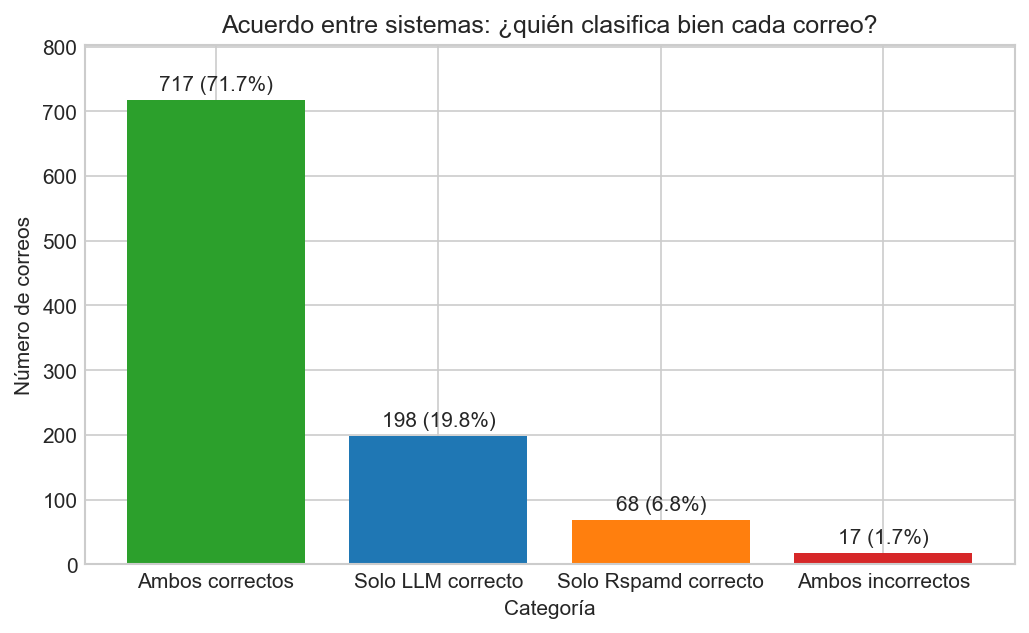

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
colores = ["tab:green", COLOR_LLM, COLOR_RSPAMD, "tab:red"]
barras = ax.bar(CATEGORIAS, conteo.values, color=colores)
ax.bar_label(barras, labels=[f"{n} ({n / len(df_ok):.1%})" for n in conteo.values], padding=3)
ax.set_title("Acuerdo entre sistemas: ¿quién clasifica bien cada correo?")
ax.set_xlabel("Categoría")
ax.set_ylabel("Número de correos")
ax.set_ylim(0, conteo.max() * 1.12)
fig.savefig(FIGURES_DIR / "error_categories.png")
plt.show()

In [11]:
# ¿De qué fuente (y por tanto de qué clase) son los correos donde solo acierta uno de los dos?
desacuerdos = df_ok[df_ok["categoria"].isin(["Solo LLM correcto", "Solo Rspamd correcto"])]
pd.crosstab(desacuerdos["categoria"], desacuerdos["source"], margins=True, margins_name="Total")

source,Phishing Pot,TREC 2007,Total
categoria,,,
Solo LLM correcto,49,149,198
Solo Rspamd correcto,57,11,68
Total,106,160,266


In [12]:
# Prueba de McNemar exacta sobre los pares discordantes: ¿la diferencia de aciertos es significativa?
solo_llm = int(conteo["Solo LLM correcto"])
solo_rspamd = int(conteo["Solo Rspamd correcto"])
p_mcnemar = binomtest(min(solo_llm, solo_rspamd), solo_llm + solo_rspamd, 0.5).pvalue
print(f"Pares discordantes: solo LLM correcto = {solo_llm}, solo Rspamd correcto = {solo_rspamd}")
print(f"McNemar exacta (bilateral): p = {p_mcnemar:.2e}")

Pares discordantes: solo LLM correcto = 198, solo Rspamd correcto = 68
McNemar exacta (bilateral): p = 6.65e-16


## 8. Error crítico: falsos negativos

Un falso negativo es un phishing clasificado como legítimo: el error más peligroso, porque el correo
llega a la bandeja del usuario.

In [13]:
phishing = df_ok[df_ok["label_real"] == 1]
fn_llm = phishing["pred_llm"] == 0
fn_rspamd = phishing["pred_rspamd"] == 0

tabla_fn = pd.DataFrame({
    "Correos": {
        f"FN de {NOMBRE_LLM}": int(fn_llm.sum()),
        f"FN de {NOMBRE_RSPAMD}": int(fn_rspamd.sum()),
        "FN de ambos simultáneamente": int((fn_llm & fn_rspamd).sum()),
        "FN solo del LLM (Rspamd sí lo detecta)": int((fn_llm & ~fn_rspamd).sum()),
        "FN solo de Rspamd (el LLM sí lo detecta)": int((~fn_llm & fn_rspamd).sum()),
        "Phishing detectado por al menos uno": int((~fn_llm | ~fn_rspamd).sum()),
    }
})
tabla_fn["% del phishing real"] = (tabla_fn["Correos"] / len(phishing) * 100).round(1)

# McNemar exacta solo sobre el phishing: ¿la diferencia de Recall entre sistemas es significativa?
n_solo_llm_fn, n_solo_rspamd_fn = int((fn_llm & ~fn_rspamd).sum()), int((~fn_llm & fn_rspamd).sum())
p_recall = binomtest(min(n_solo_llm_fn, n_solo_rspamd_fn), n_solo_llm_fn + n_solo_rspamd_fn, 0.5).pvalue
print(f"McNemar exacta sobre el phishing (diferencia de Recall): p = {p_recall:.3f}")
tabla_fn

McNemar exacta sobre el phishing (diferencia de Recall): p = 0.497


,Correos,% del phishing real
FN de Sistema LLM+MCP,67,13.4
FN de Rspamd 4.1.5,59,11.8
FN de ambos simultáneamente,10,2.0
FN solo del LLM (Rspamd sí lo detecta),57,11.4
FN solo de Rspamd (el LLM sí lo detecta),49,9.8
Phishing detectado por al menos uno,490,98.0


In [14]:
# Fuente de los falsos negativos de cada sistema
fn_por_fuente = pd.DataFrame({
    f"FN {NOMBRE_LLM}": phishing.loc[fn_llm, "source"].value_counts(),
    f"FN {NOMBRE_RSPAMD}": phishing.loc[fn_rspamd, "source"].value_counts(),
    "FN de ambos": phishing.loc[fn_llm & fn_rspamd, "source"].value_counts(),
    "Phishing reales en la fuente": phishing["source"].value_counts(),
}).fillna(0).astype(int)
fn_por_fuente

,FN Sistema LLM+MCP,FN Rspamd 4.1.5,FN de ambos,Phishing reales en la fuente
source,,,,
Phishing Pot,67,59,10,500


In [15]:
# Qué tan cerca del umbral quedaron los falsos negativos de cada sistema
pd.DataFrame({
    f"FN {NOMBRE_LLM} (puntaje_riesgo)": phishing.loc[fn_llm, "puntaje_riesgo_llm"].describe(),
    f"FN {NOMBRE_RSPAMD} (score crudo)": phishing.loc[fn_rspamd, "rspamd_score"].describe(),
}).round(2)

,FN Sistema LLM+MCP (puntaje_riesgo),FN Rspamd 4.1.5 (score crudo)
count,67.00,59.00
mean,0.16,4.59
std,0.07,1.23
min,0.05,0.70
25%,0.15,3.68
50%,0.15,4.84
75%,0.20,5.70
max,0.35,5.90


## 9. Comparación visual de métricas

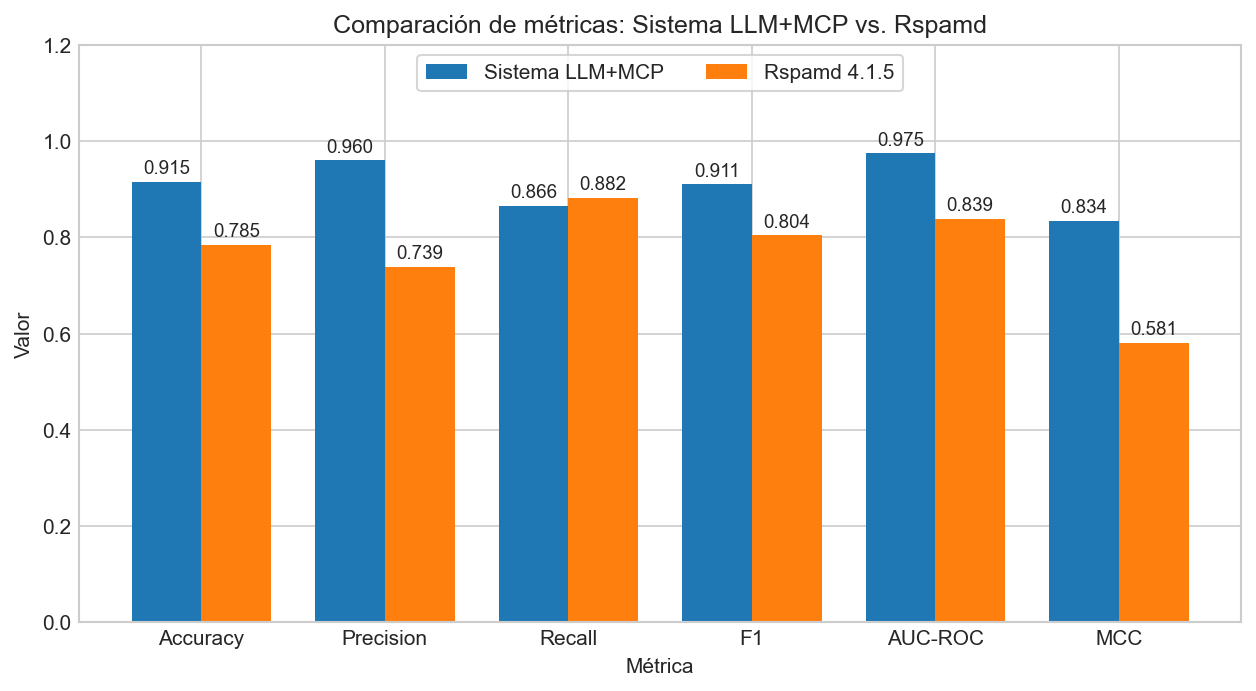

In [16]:
metricas_grafico = ["Accuracy", "Precision", "Recall (Sensitivity)", "F1", "AUC-ROC", "MCC"]
etiquetas_x = ["Accuracy", "Precision", "Recall", "F1", "AUC-ROC", "MCC"]
x = np.arange(len(metricas_grafico))
ancho = 0.38

fig, ax = plt.subplots(figsize=(10, 5))
barras_llm = ax.bar(x - ancho / 2, tabla_metricas.loc[metricas_grafico, NOMBRE_LLM], ancho,
                    color=COLOR_LLM, label=NOMBRE_LLM)
barras_rspamd = ax.bar(x + ancho / 2, tabla_metricas.loc[metricas_grafico, NOMBRE_RSPAMD], ancho,
                       color=COLOR_RSPAMD, label=NOMBRE_RSPAMD)
ax.bar_label(barras_llm, fmt="%.3f", padding=2, fontsize=9)
ax.bar_label(barras_rspamd, fmt="%.3f", padding=2, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(etiquetas_x)
ax.set_ylim(0, 1.2)
ax.set_xlabel("Métrica")
ax.set_ylabel("Valor")
ax.set_title("Comparación de métricas: Sistema LLM+MCP vs. Rspamd")
ax.legend(loc="upper center", ncol=2, frameon=True)
fig.savefig(FIGURES_DIR / "metrics_comparison.png")
plt.show()

## 10. Conclusiones del análisis

> Las cifras de esta sección corresponden a los resultados evaluados el 2026-10-04 (1,000 correos, 0 errores en ambos sistemas). Si se regeneran los archivos de resultados, hay que actualizar este texto con las tablas de las secciones anteriores.

| Aspecto | Sistema LLM+MCP | Rspamd 4.1.5 | Mejor |
|---|---|---|---|
| Recall (phishing detectado) | 0.866 (433 de 500) | 0.882 (441 de 500) | Rspamd, por 8 correos (diferencia no significativa, p = 0.50) |
| FNR (phishing no detectado) | 0.134 (67) | 0.118 (59) | Rspamd |
| Precision | 0.960 | 0.739 | LLM+MCP |
| FPR (falsas alarmas) | 0.036 (18 de 500) | 0.312 (156 de 500) | LLM+MCP |
| F1 | 0.911 | 0.804 | LLM+MCP |
| MCC | 0.834 | 0.581 | LLM+MCP |
| AUC-ROC | 0.975 | 0.839 | LLM+MCP |
| Accuracy | 0.915 | 0.785 | LLM+MCP |
| Costo total / tiempo mediano por correo | USD 21.87 / 22.1 s | USD 0.00 / 0.27 s | Rspamd |

**¿Qué sistema detecta más phishing?** Rspamd detecta ligeramente más: 441 contra 433 de los 500 phishing (Recall 0.882 vs. 0.866). La diferencia es de 8 correos y no es estadísticamente significativa (McNemar exacta sobre el phishing, p = 0.50), así que en capacidad de detección ambos sistemas están prácticamente empatados. Lo que sí difiere es *cuáles* correos se le escapan a cada uno: solo 10 phishing pasan desapercibidos para los dos a la vez, mientras que 57 los detecta solo Rspamd y 49 solo el LLM. Entre ambos cubren 490 de los 500 (98 %).

**¿Qué sistema tiene menos falsas alarmas?** El sistema LLM+MCP, por amplio margen: marca como phishing 18 de los 500 correos legítimos (FPR 3.6 %), frente a 156 de Rspamd (FPR 31.2 %). Esto explica casi toda la ventaja del LLM en Precision (0.960 vs. 0.739), F1, MCC y Accuracy. La diferencia global de aciertos sí es significativa (198 correos donde solo acierta el LLM contra 68 donde solo acierta Rspamd; McNemar exacta, p < 0.001). El AUC-ROC (0.975 vs. 0.839) indica además que la ventaja no depende del umbral elegido: los histogramas muestran que el LLM separa las dos clases en extremos opuestos del puntaje, mientras que en Rspamd los legítimos y el phishing se solapan justo alrededor del umbral de 6.0.

**¿En qué tipos de correos falla cada uno?** Los errores de Rspamd se concentran en los legítimos de TREC 2007: de los 198 correos donde solo acierta el LLM, 149 son legítimos que Rspamd marcó como phishing. Hay que leer este resultado con una limitación del conjunto de evaluación en mente: los correos de TREC tienen encabezados reconstruidos (From, To, Subject, Date y Message-ID, sin cadena `Received` ni autenticación), y Rspamd puntúa en buena parte por estructura e infraestructura del mensaje, de modo que parte de sus falsos positivos puede deberse a esa reconstrucción y no al contenido. Los errores del LLM son de otro tipo: sus 67 falsos negativos son phishing que el modelo considera legítimo con bastante seguridad (puntaje de riesgo mediano de 0.15, máximo de 0.35, lejos del umbral de 0.5), mientras que los 59 falsos negativos de Rspamd quedan cerca del umbral (score mediano de 4.84 sobre 6.0), por lo que bajarían con un umbral algo menor, a costa de aún más falsas alarmas.

**Implicación práctica.** Con un Recall equivalente, el LLM+MCP genera cerca de nueve veces menos falsas alarmas, lo que lo hace mucho más utilizable como filtro que actúa sobre el correo del usuario: con Rspamd en este umbral, casi un tercio del correo legítimo quedaría marcado. El costo es operativo: USD 21.87 y una mediana de 22 s por correo para el LLM, contra un costo nulo y 0.27 s para Rspamd. Como los dos sistemas fallan en correos distintos, el resultado apunta a un uso complementario más que a un reemplazo: Rspamd como primer filtro rápido y barato, y el sistema LLM+MCP como segunda opinión sobre los correos que Rspamd marca o deja cerca del umbral, donde aporta la reducción de falsos positivos y una explicación del veredicto (arquetipo de ingeniería social asignado en el 91.4 % del phishing).

## 11. Análisis cualitativo de errores por sistema

Las secciones anteriores comparan *cuánto* acierta cada sistema; esta mira *en qué* se equivoca cada uno.
Usa las mismas predicciones que el resto del notebook (campo `clasificacion` de cada archivo) y, si está
disponible, `eval_external.csv` para obtener la fuente, el asunto y el remitente de cada correo.

In [17]:
from IPython.display import HTML, display

# Detalle por correo: predicciones de ambos sistemas + arquetipo e indicadores de VirusTotal del LLM
det = df_ok.merge(df_llm[["id", "arquetipo_label", "vt_indicadores", "vt_resultados"]], on="id", validate="one_to_one")
det["arquetipo_label"] = det["arquetipo_label"].fillna("(sin arquetipo asignado)")
det["n_indicadores_vt"] = det["vt_indicadores"].str.len()
det["n_vt_maliciosos"] = det["vt_resultados"].apply(
    lambda res: sum(str(v).lower().startswith(("malicious", "suspicious")) for v in res.values())
)

# source, asunto y remitente no vienen en los JSONL: se obtienen de eval_external.csv por id
RUTA_CSV = BASE / "external_eval" / "eval_external.csv"
TIENE_META = RUTA_CSV.exists()
if TIENE_META:
    meta = pd.read_csv(RUTA_CSV, usecols=["id", "source", "subject", "sender", "body"])
    meta["es_respuesta"] = meta["subject"].fillna("").str.match(r"(?i)\s*(re|fwd?):")
    meta["cuerpo_no_ascii"] = meta["body"].fillna("").str.contains(r"[^\x00-\x7f]")
    meta["dominio_remitente"] = meta["sender"].fillna("").str.extract(r"@([\w.-]+)", expand=False).str.lower()
    meta["source_csv"] = meta["source"].map(FUENTES)
    det = det.merge(meta.drop(columns=["body", "source"]), on="id", how="left", validate="one_to_one")
    det["source"] = det["source_csv"].fillna(det["source"])
    det = det.drop(columns="source_csv")
    print(f"Metadatos cargados de {RUTA_CSV.name}: {det['subject'].notna().sum()} correos con asunto")
else:
    print(f"No se encontró {RUTA_CSV}; se omiten los análisis por asunto/remitente y source se deriva del id.")

es_phishing = det["label_real"] == 1
FN_LLM = det[es_phishing & (det["pred_llm"] == 0)]
FN_RSPAMD = det[es_phishing & (det["pred_rspamd"] == 0)]
FP_LLM = det[~es_phishing & (det["pred_llm"] == 1)]
FP_RSPAMD = det[~es_phishing & (det["pred_rspamd"] == 1)]
print(f"FN LLM: {len(FN_LLM)} | FN Rspamd: {len(FN_RSPAMD)} | FP LLM: {len(FP_LLM)} | FP Rspamd: {len(FP_RSPAMD)}")


def lado_a_lado(tablas: dict, alto_max: int = 420) -> None:
    """Muestra varias tablas una junto a otra (cada una con scroll propio si es larga)."""
    bloques = []
    for titulo, tabla in tablas.items():
        bloques.append(
            f'<div style="flex: 1; min-width: 320px;"><h4 style="margin: 0 0 6px 0;">{titulo}</h4>'
            f'<div style="max-height: {alto_max}px; overflow: auto;">{tabla.to_html(max_rows=None)}</div></div>'
        )
    display(HTML('<div style="display: flex; gap: 24px; align-items: flex-start; flex-wrap: wrap;">' + "".join(bloques) + "</div>"))

Metadatos cargados de eval_external.csv: 997 correos con asunto
FN LLM: 67 | FN Rspamd: 59 | FP LLM: 18 | FP Rspamd: 156


### A. Tabla de errores cruzados

In [18]:
clase = det["label_real"].map({1: "Phishing", 0: "Legítimo"})
tabla_cruzada = pd.crosstab(det["categoria"], clase).reindex(CATEGORIAS, fill_value=0)
tabla_cruzada.columns.name = None
tabla_cruzada.insert(0, "Correos", tabla_cruzada.sum(axis=1))
tabla_cruzada.insert(1, "% del total", (tabla_cruzada["Correos"] / len(det) * 100).round(1))
tabla_cruzada

,Correos,% del total,Legítimo,Phishing
categoria,,,,
Ambos correctos,717,71.7,333,384
Solo LLM correcto,198,19.8,149,49
Solo Rspamd correcto,68,6.8,11,57
Ambos incorrectos,17,1.7,7,10


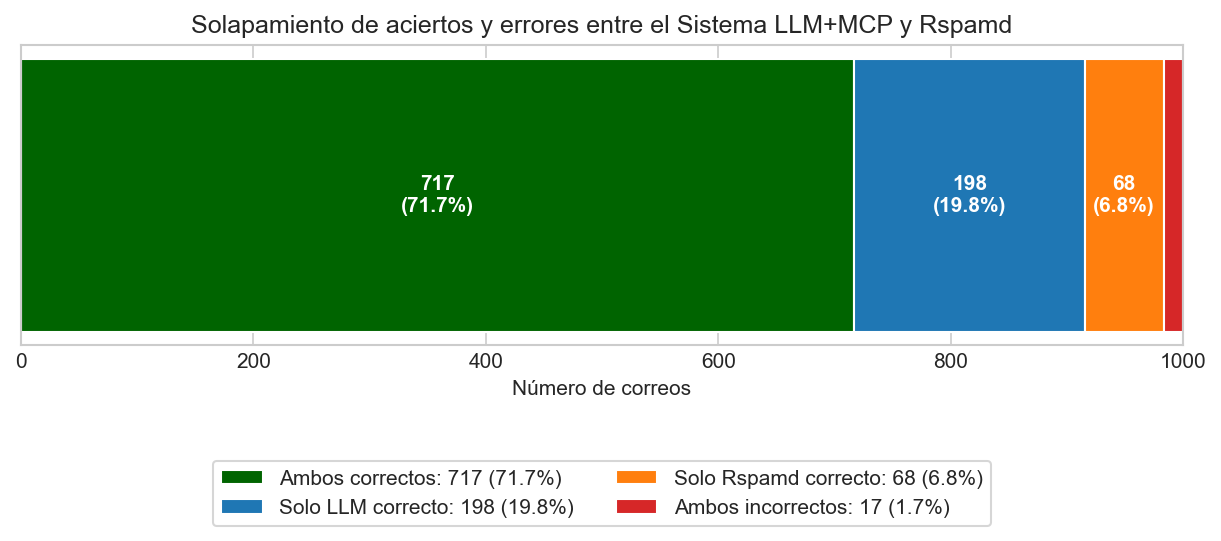

In [19]:
fig, ax = plt.subplots(figsize=(10, 2.6))
colores_cat = ["darkgreen", "tab:blue", "tab:orange", "tab:red"]
izquierda = 0
for categoria, color in zip(CATEGORIAS, colores_cat):
    n = int(tabla_cruzada.loc[categoria, "Correos"])
    ax.barh(["Correos"], [n], left=izquierda, color=color, edgecolor="white",
            label=f"{categoria}: {n} ({n / len(det):.1%})")
    if n / len(det) >= 0.05:
        ax.text(izquierda + n / 2, 0, f"{n}\n({n / len(det):.1%})", ha="center", va="center",
                color="white", fontweight="bold")
    izquierda += n

ax.set_xlim(0, len(det))
ax.set_xlabel("Número de correos")
ax.set_yticks([])
ax.set_title("Solapamiento de aciertos y errores entre el Sistema LLM+MCP y Rspamd")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=2, frameon=True)
fig.savefig(FIGURES_DIR / "error_overlap.png")
plt.show()

### B. ¿En qué falla cada uno? Falsos negativos

Phishing real que cada sistema dejó pasar como legítimo. A la izquierda los del LLM (con el arquetipo que
asignó y cuántos indicadores de red consultó en VirusTotal); a la derecha los de Rspamd.

In [20]:
tabla_fn_llm = (FN_LLM[["id", "puntaje_riesgo_llm", "arquetipo_label", "n_indicadores_vt"]]
                .rename(columns={"puntaje_riesgo_llm": "puntaje_riesgo", "n_indicadores_vt": "indicadores VT"})
                .sort_values("puntaje_riesgo", ascending=False).reset_index(drop=True))
tabla_fn_llm["arquetipo_label"] = tabla_fn_llm["arquetipo_label"].str.slice(0, 70)

tabla_fn_rspamd = (FN_RSPAMD[["id", "rspamd_score", "rspamd_action"]]
                   .sort_values("rspamd_score", ascending=False).reset_index(drop=True))

lado_a_lado({
    f"FN del {NOMBRE_LLM} ({len(tabla_fn_llm)} correos)": tabla_fn_llm,
    f"FN de {NOMBRE_RSPAMD} ({len(tabla_fn_rspamd)} correos)": tabla_fn_rspamd,
})

,id,puntaje_riesgo,arquetipo_label,indicadores VT
0,phishing_pot_sample-1255,0.35,Phishing de verificacion y suspension de cuenta,0
1,phishing_pot_sample-1044,0.35,Spam farmaceutico y de pastillas para adelgazar con frases de marketin,0
2,phishing_pot_sample-1352,0.35,Spam farmaceutico y de pastillas para adelgazar con frases de marketin,4
3,phishing_pot_sample-1382,0.25,Spam farmaceutico y de pastillas para adelgazar con frases de marketin,2
4,phishing_pot_sample-1427,0.25,Esquema de dinero facil y ganancias garantizadas (estilo loteria/MLM),0
5,phishing_pot_sample-1373,0.25,Spam ofuscado de medicamentos genericos (evasion de filtros),0
6,phishing_pot_sample-1258,0.25,Spam de acciones bursatiles 'pump and dump' (boletines de inversion fa,1
7,phishing_pot_sample-1261,0.25,Spam de acciones bursatiles 'pump and dump' (boletines de inversion fa,1
8,phishing_pot_sample-1364,0.25,Phishing de verificacion y suspension de cuenta,2
9,phishing_pot_sample-1412,0.25,Spam farmaceutico y de pastillas para adelgazar con frases de marketin,1


In [21]:
# ¿Qué tipos de phishing no detecta cada sistema? Se usa el arquetipo asignado por el LLM como
# descriptor del tipo de correo (es la única etiqueta de "tipo" disponible para ambos sistemas).
phishing_por_arquetipo = det.loc[es_phishing, "arquetipo_label"].value_counts()


def fn_por_arquetipo(fn: pd.DataFrame) -> pd.DataFrame:
    tabla = pd.DataFrame({"FN": fn["arquetipo_label"].value_counts(), "Phishing con ese arquetipo": phishing_por_arquetipo})
    tabla = tabla.dropna(subset=["Phishing con ese arquetipo"]).fillna(0).astype(int)
    tabla["% no detectado"] = (tabla["FN"] / tabla["Phishing con ese arquetipo"] * 100).round(1)
    tabla.index = tabla.index.str.slice(0, 70)
    return tabla[tabla["FN"] > 0].sort_values("FN", ascending=False)


lado_a_lado({
    f"FN del {NOMBRE_LLM} por arquetipo": fn_por_arquetipo(FN_LLM),
    f"FN de {NOMBRE_RSPAMD} por arquetipo (asignado por el LLM)": fn_por_arquetipo(FN_RSPAMD),
})

,FN,Phishing con ese arquetipo,% no detectado
arquetipo_label,,,
Spam farmaceutico y de pastillas para adelgazar con frases de marketin,38,182,20.9
Spam de acciones bursatiles 'pump and dump' (boletines de inversion fa,7,18,38.9
Esquema de dinero facil y ganancias garantizadas (estilo loteria/MLM),6,39,15.4
Spam ofuscado de medicamentos genericos (evasion de filtros),6,8,75.0
Phishing de verificacion y suspension de cuenta,4,161,2.5
Spam de atraccion y mejora sexual masculina con tono agresivo y pseudo,4,15,26.7
Spam ofuscado de agrandamiento masculino con pseudo-respaldo medico (e,1,6,16.7
Venta de software pirata a precio muy bajo,1,2,50.0
,FN,Phishing con ese arquetipo,% no detectado


In [22]:
# Rspamd: qué acción tomó en sus FN. LLM: ¿influyen los indicadores de VirusTotal en sus FN?
accion_fn = FN_RSPAMD["rspamd_action"].value_counts().rename("FN de Rspamd").to_frame()
accion_fn["%"] = (accion_fn["FN de Rspamd"] / len(FN_RSPAMD) * 100).round(1)

TP_LLM = det[es_phishing & (det["pred_llm"] == 1)]
vt_fn_vs_tp = pd.DataFrame({
    grupo: {
        "Correos": str(len(d)),
        "Indicadores VT por correo (media)": f"{d['n_indicadores_vt'].mean():.2f}",
        "% sin ningún indicador VT": f"{(d['n_indicadores_vt'] == 0).mean() * 100:.1f}",
        "Correos con algún veredicto VT malicioso": str(int((d["n_vt_maliciosos"] > 0).sum())),
    }
    for grupo, d in [("FN del LLM", FN_LLM), ("TP del LLM (phishing detectado)", TP_LLM)]
})

lado_a_lado({
    "Acción de Rspamd en sus FN": accion_fn,
    "Indicadores de VirusTotal: FN vs. TP del LLM": vt_fn_vs_tp,
})

veredictos = pd.Series([str(v) for res in det["vt_resultados"] for v in res.values()])
tipo_veredicto = np.select([veredictos.str.startswith("clean"), veredictos.str.startswith("error")],
                           ["clean", "error en la consulta"], default="malicious / suspicious")
print("Veredictos de VirusTotal en los 1,000 correos:", pd.Series(tipo_veredicto).value_counts().to_dict())

,FN de Rspamd,%
rspamd_action,,
greylist,39,66.1
no action,20,33.9
,FN del LLM,TP del LLM (phishing detectado)
Correos,67,433
Indicadores VT por correo (media),1.15,1.09
% sin ningún indicador VT,41.8,46.4
Correos con algún veredicto VT malicioso,0,0


Veredictos de VirusTotal en los 1,000 correos: {'clean': 1568, 'error en la consulta': 144}


### C. ¿En qué falla cada uno? Falsos positivos

Correos legítimos (TREC 2007) que cada sistema marcó como phishing.

In [23]:
fp_llm_arquetipo = FP_LLM["arquetipo_label"].value_counts().rename("FP del LLM").to_frame()
fp_llm_arquetipo.index = fp_llm_arquetipo.index.str.slice(0, 70)

fp_rspamd_accion = FP_RSPAMD["rspamd_action"].value_counts().rename("FP de Rspamd").to_frame()

scores_fp = pd.DataFrame({
    f"FP {NOMBRE_LLM} (puntaje_riesgo)": FP_LLM["puntaje_riesgo_llm"].describe(),
    f"FP {NOMBRE_RSPAMD} (score crudo)": FP_RSPAMD["rspamd_score"].describe(),
}).round(2)

lado_a_lado({
    f"FP del {NOMBRE_LLM} por arquetipo asignado ({len(FP_LLM)} correos)": fp_llm_arquetipo,
    f"FP de {NOMBRE_RSPAMD} por acción ({len(FP_RSPAMD)} correos)": fp_rspamd_accion,
    "Distribución de scores en los FP": scores_fp,
})

,FP del LLM
arquetipo_label,
Spam de acciones bursatiles 'pump and dump' (boletines de inversion fa,7
Suplantacion de boletin de noticias (alertas CNN falsas),4
(sin arquetipo asignado),3
Spam farmaceutico y de pastillas para adelgazar con frases de marketin,2
Venta de software pirata a precio muy bajo,1
Spam de hipotecas y prestamos preaprobados,1
,FP de Rspamd
rspamd_action,
add header,156


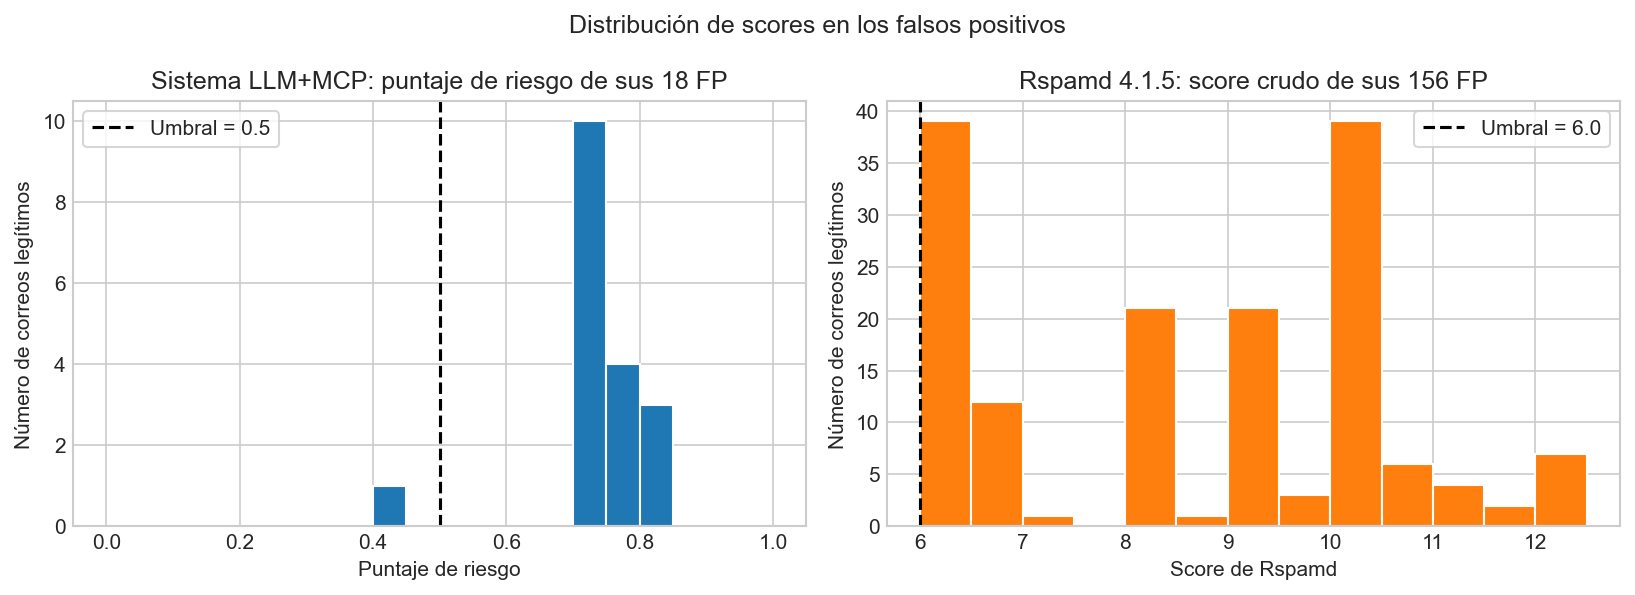

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(FP_LLM["puntaje_riesgo_llm"], bins=np.linspace(0, 1, 21), color=COLOR_LLM, edgecolor="white")
axes[0].axvline(THRESHOLD_LLM, linestyle="--", color="black", label=f"Umbral = {THRESHOLD_LLM}")
axes[0].set_title(f"{NOMBRE_LLM}: puntaje de riesgo de sus {len(FP_LLM)} FP")
axes[0].set_xlabel("Puntaje de riesgo")
axes[0].set_ylabel("Número de correos legítimos")
axes[0].legend(frameon=True)

axes[1].hist(FP_RSPAMD["rspamd_score"], bins=np.arange(THRESHOLD_RSPAMD, FP_RSPAMD["rspamd_score"].max() + 0.5, 0.5),
             color=COLOR_RSPAMD, edgecolor="white")
axes[1].axvline(THRESHOLD_RSPAMD, linestyle="--", color="black", label=f"Umbral = {THRESHOLD_RSPAMD}")
axes[1].set_title(f"{NOMBRE_RSPAMD}: score crudo de sus {len(FP_RSPAMD)} FP")
axes[1].set_xlabel("Score de Rspamd")
axes[1].set_ylabel("Número de correos legítimos")
axes[1].legend(frameon=True)

fig.suptitle("Distribución de scores en los falsos positivos")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fp_score_distributions.png")
plt.show()

In [25]:
# ¿Qué correos legítimos confunden a cada sistema? (requiere eval_external.csv)
if TIENE_META:
    legitimos = det[~es_phishing]

    def tasa_fp(columna: str, col_pred: str = "pred_rspamd") -> pd.DataFrame:
        tabla = legitimos.groupby(columna)[col_pred].agg(Legítimos="count", FP="sum")
        tabla["% marcado como phishing"] = (tabla["FP"] / tabla["Legítimos"] * 100).round(1)
        return tabla

    por_ascii = tasa_fp("cuerpo_no_ascii").rename(index={True: "Cuerpo con caracteres no ASCII", False: "Cuerpo solo ASCII"})
    por_respuesta = tasa_fp("es_respuesta").rename(index={True: "Asunto con Re:/Fwd:", False: "Asunto sin Re:/Fwd:"})
    por_dominio = tasa_fp("dominio_remitente").sort_values("Legítimos", ascending=False).head(12)

    lado_a_lado({
        "FP de Rspamd según características del correo": pd.concat([por_ascii, por_respuesta]),
        "FP de Rspamd por dominio del remitente (12 más frecuentes)": por_dominio,
    })

    asuntos_fp_llm = (FP_LLM[["id", "puntaje_riesgo_llm", "subject", "dominio_remitente", "pred_rspamd"]]
                      .rename(columns={"puntaje_riesgo_llm": "puntaje_riesgo", "subject": "asunto",
                                       "pred_rspamd": "Rspamd también lo marca"})
                      .sort_values("puntaje_riesgo", ascending=False).reset_index(drop=True))
    asuntos_fp_llm["asunto"] = asuntos_fp_llm["asunto"].fillna("").str.slice(0, 70)
    asuntos_fp_llm["Rspamd también lo marca"] = asuntos_fp_llm["Rspamd también lo marca"].map({1: "sí", 0: "no"})
    lado_a_lado({f"Los {len(FP_LLM)} FP del {NOMBRE_LLM}": asuntos_fp_llm}, alto_max=520)
else:
    print("Sin eval_external.csv no se puede caracterizar el contenido de los falsos positivos.")

,Legítimos,FP,% marcado como phishing
Cuerpo solo ASCII,403,60,14.9
Cuerpo con caracteres no ASCII,97,96,99.0
Asunto sin Re:/Fwd:,271,95,35.1
Asunto con Re:/Fwd:,229,61,26.6
,Legítimos,FP,% marcado como phishing
dominio_remitente,,,
gmail.com,65,5,7.7
samba.org,63,11,17.5
mail.cnn.com,20,20,100.0
cbsig.com,16,12,75.0


,id,puntaje_riesgo,asunto,dominio_remitente,Rspamd también lo marca
0,trec_2007_97,0.85,[Slashdot] Headlines for 2007-05-06,slashdot.org,no
1,trec_2007_438,0.85,[Slashdot] Headlines for 2007-04-16,slashdot.org,no
2,trec_2007_171,0.85,File Handling. Reading and Writting.,brq.com,no
3,trec_2007_329,0.78,[Reform] adobe photoshop cs3 extended $89,realtysubmit.com,no
4,trec_2007_376,0.78,BUTUH UANG TUNAI YG CEPAT & MUDAH...???,gmail.com,sí
5,trec_2007_161,0.78,"Stock Notification for Netflix, Inc.",broadcast.shareholder.com,no
6,trec_2007_79,0.76,CNN Alerts: My Custom Alert,mail.cnn.com,sí
7,trec_2007_233,0.72,"Information for Netflix, Inc.",broadcast.shareholder.com,no
8,trec_2007_266,0.72,CNN Alerts: bush,mail.cnn.com,sí
9,trec_2007_278,0.72,Daily Power Report,calcium.netcontentinc.net,sí


**Lectura de los falsos positivos.**

- **LLM+MCP (18 FP):** son boletines y notificaciones automáticas legítimas (alertas de CNN, titulares de Slashdot,
  notificaciones de cotizaciones bursátiles, reportes diarios) que el modelo asocia con arquetipos de spam
  («pump and dump» en 7 casos, suplantación de boletín de noticias en 4). No son errores dudosos: el puntaje
  mediano es 0.72. Además, por su asunto, al menos 4 de los 18 parecen spam real que TREC etiqueta como
  legítimo (p. ej. «adobe photoshop cs3 extended $89» o «BUTUH UANG TUNAI YG CEPAT & MUDAH»), así que no
  todos son errores del modelo. Rspamd coincide en 7 de los 18.
- **Rspamd (156 FP):** todos quedan en la acción `add header`, ninguno en `reject`, con score mediano de 9.0.
  El factor que mejor los explica no es el contenido sino el formato: se marca como phishing el 99 % de los
  legítimos cuyo cuerpo tiene caracteres no ASCII (96 de 97), frente al 14.9 % de los que son solo ASCII
  (60 de 403). Varios remitentes de boletines (CNN, AccuWeather, Fox News) tienen el 100 % de sus correos marcados.
- **Limitación a declarar:** los correos de TREC en `eval_external.csv` tienen encabezados reconstruidos, sin
  `Content-Type`, `Content-Transfer-Encoding`, `Received` ni firmas. Un cuerpo con caracteres de 8 bits sin
  esos encabezados es precisamente lo que penalizan reglas estructurales de Rspamd (en una muestra de 60
  legítimos se observaron `R_BAD_CTE_7BIT`, `HFILTER_HOSTNAME_UNKNOWN`, `DMARC_POLICY_REJECT` y `FAKE_REPLY`).
  Es decir, una parte importante de los FP de Rspamd se debe a cómo se reconstruyó el correo y no al mensaje
  original; su FPR real sobre correo con encabezados completos sería probablemente menor. Esa atribución a
  reglas concretas no está medida sobre los 156 FP, porque los símbolos de Rspamd no se guardan en el JSONL.

### D. Conclusión de complementariedad

> Cifras de la corrida del 2026-10-04; si se regeneran los resultados hay que actualizar este texto con las tablas de arriba.

| Pregunta | Respuesta |
|---|---|
| 1. Phishing que el LLM detecta y Rspamd **no** (FN de Rspamd que el LLM clasifica bien) | **49** de los 59 FN de Rspamd |
| 2. Phishing que Rspamd detecta y el LLM **no** (FN del LLM que Rspamd clasifica bien) | **57** de los 67 FN del LLM |
| 3. Phishing que **ninguno** de los dos detecta | **10** de 500 (2.0 %) |
| Contando también los legítimos: correos donde solo acierta el LLM / solo acierta Rspamd | 198 / 68 |

**Ensemble teórico (OR lógico: se marca phishing si cualquiera de los dos lo marca).**

| Sistema | Recall | Precision | FPR | F1 |
|---|---|---|---|---|
| Sistema LLM+MCP | 0.866 | 0.960 | 0.036 | 0.911 |
| Rspamd | 0.882 | 0.739 | 0.312 | 0.804 |
| Ensemble OR | **0.980** (490 de 500) | 0.746 | 0.334 (167 FP) | 0.847 |
| Ensemble AND (ambos deben marcarlo) | 0.768 (384 de 500) | 0.982 | 0.014 (7 FP) | 0.862 |

**Interpretación.** Los dos sistemas son complementarios en detección: cada uno recupera la gran mayoría de lo
que se le escapa al otro, y solo 10 phishing pasan por ambos. Combinados con un OR, el Recall teórico sube de
0.866 / 0.882 a 0.980. El costo es que el OR también hereda las falsas alarmas de los dos (167 legítimos
marcados, FPR 33.4 %), casi todas de Rspamd; por eso su F1 (0.847) queda por debajo del LLM solo (0.911). El
OR solo conviene si el objetivo es minimizar el phishing no detectado y se tolera revisar muchas alertas, o si
antes se corrige el exceso de falsos positivos de Rspamd (ver la limitación de la sección C).

**En qué falla cada uno.** Los fallos del LLM se concentran en **spam comercial** más que en phishing de
credenciales: 63 de sus 67 FN tienen arquetipos de spam (38 farmacéutico, 7 «pump and dump», 6 dinero fácil,
6 medicamentos ofuscados, 4 mejora sexual, 2 otros) y solo 4 son de «verificación y suspensión de cuenta», de
161 correos con ese arquetipo (2.5 %). El modelo reconoce el tipo de correo (le asigna arquetipo) pero no lo
considera phishing, con puntajes bajos (mediana 0.15). Rspamd, en cambio, deja pasar 18 de esos 161 correos de
suplantación de cuenta (11.2 %), más de cuatro veces lo que el LLM, y sus FN quedan cerca del umbral (39 en
`greylist`, 20 en `no action`). Esto respalda la idea de que el LLM aporta sobre todo en phishing de suplantación
y Rspamd en spam masivo.

Dos matices que los datos **no** respaldan y conviene no afirmar en la tesis:

- *«El LLM falla cuando no hay señales de URL»*: sus FN tienen prácticamente los mismos indicadores de red que
  sus aciertos (1.15 vs. 1.09 por correo; 41.8 % vs. 46.4 % sin ningún indicador). La ausencia de URLs no
  distingue sus errores.
- *VirusTotal como señal*: en los 1,000 correos VirusTotal no devolvió ningún veredicto malicioso (1,568
  `clean` y 144 consultas con error). En este conjunto la detección del LLM descansa en el análisis del texto y
  el arquetipo, no en la reputación de URLs o dominios.
- Rspamd tampoco falla solo en suplantación: su mayor grupo de FN también es spam farmacéutico (25 de 182,
  13.7 %), con una tasa parecida a la que tiene en suplantación de cuenta.

## 12. Análisis de patrones semánticos y señales detectadas

Las secciones anteriores miden *cuánto* acierta el sistema; esta describe *qué* identifica en los correos:
el patrón semántico (arquetipo de ataque) que el MCP `archetype` asigna a cada correo y las señales técnicas
(indicadores de red consultados en VirusTotal). Usa los 1,000 correos evaluados en modo veredicto
(`results_raw.jsonl`) a través de la tabla `det` de la sección 11.

### A. Distribución de arquetipos

Frecuencia de cada `arquetipo_label` en los 1,000 correos. El color de cada barra es la **tasa de detección**:
el porcentaje de correos con ese arquetipo que el sistema clasificó como phishing.

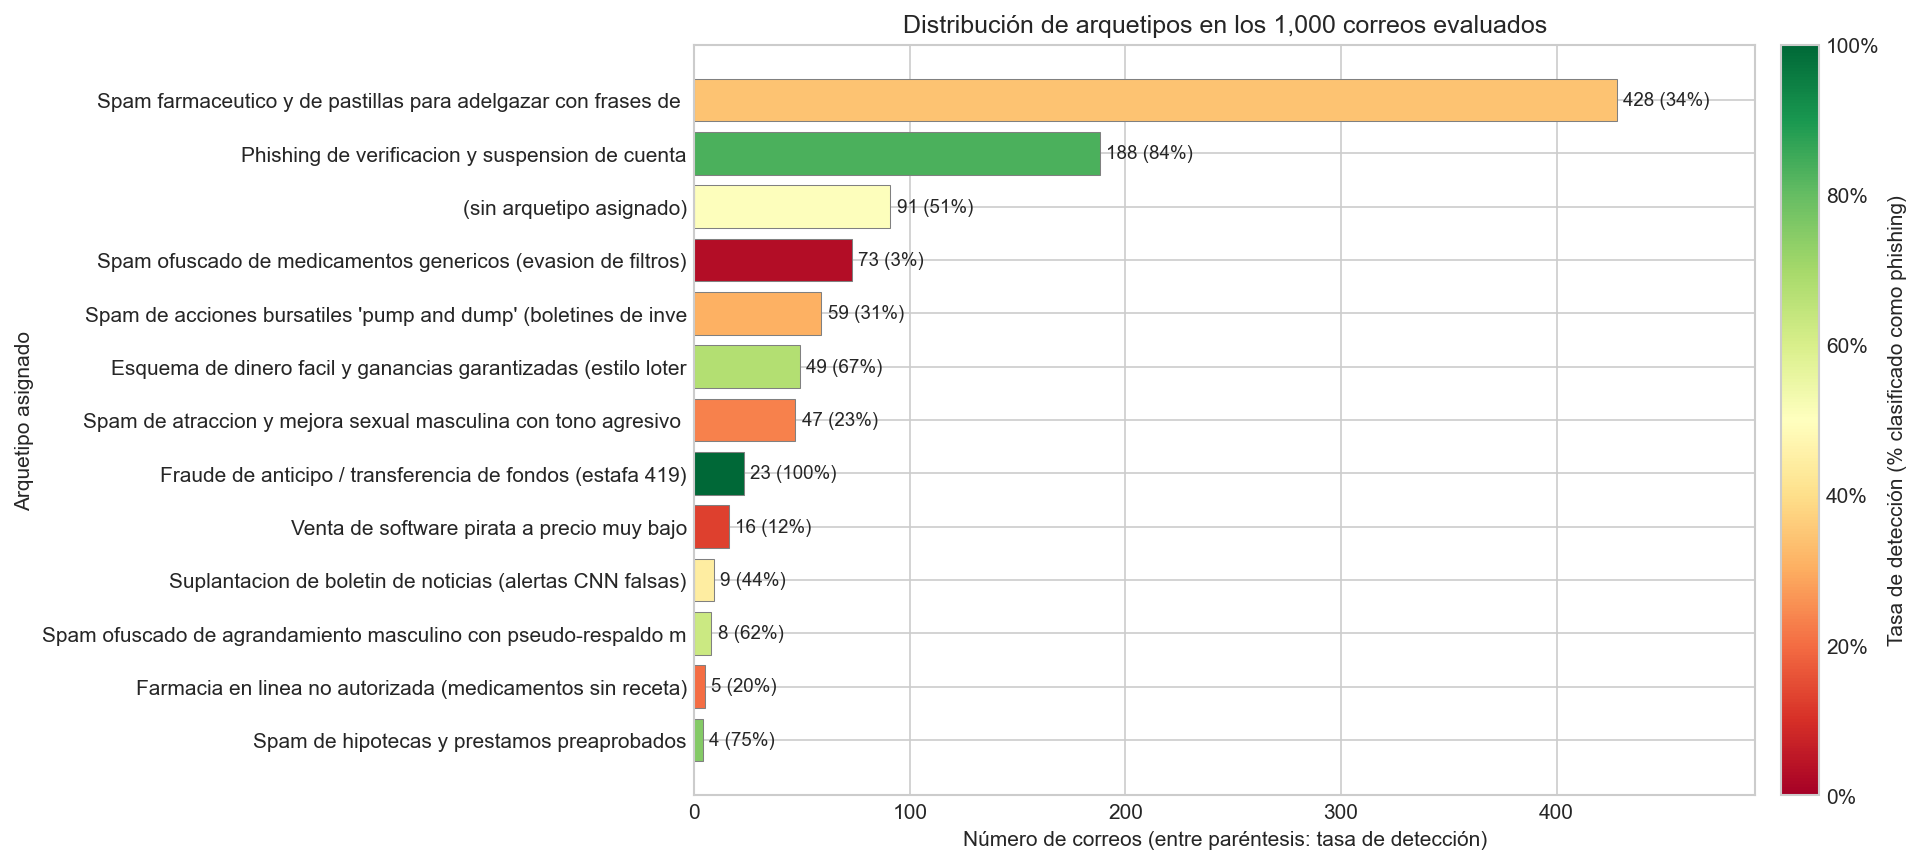

In [26]:
UMBRAL_DETECTA_BIEN, UMBRAL_DETECTA_MAL = 0.90, 0.50

# det ya trae "(sin arquetipo asignado)" en los correos donde el MCP archetype no devolvió arquetipo
por_arquetipo = det.groupby("arquetipo_label").agg(
    total=("id", "count"),
    detectados=("pred_llm", "sum"),
    phishing_reales=("label_real", "sum"),
)
por_arquetipo["phishing_detectados"] = (
    det[es_phishing].groupby("arquetipo_label")["pred_llm"].sum().reindex(por_arquetipo.index, fill_value=0)
)
por_arquetipo["tasa_deteccion"] = por_arquetipo["detectados"] / por_arquetipo["total"]
# Recall dentro del arquetipo: solo sobre los correos que realmente son phishing (NaN si no hay ninguno)
por_arquetipo["recall_phishing"] = por_arquetipo["phishing_detectados"] / por_arquetipo["phishing_reales"].replace(0, np.nan)
por_arquetipo = por_arquetipo.sort_values("total", ascending=False)

orden = por_arquetipo.sort_values("total")  # barh dibuja de abajo hacia arriba
fig, ax = plt.subplots(figsize=(11, 6.5))
barras = ax.barh(orden.index.str.slice(0, 62), orden["total"],
                 color=plt.cm.RdYlGn(orden["tasa_deteccion"]), edgecolor="gray", linewidth=0.5)
ax.bar_label(barras, labels=[f"{n} ({tasa:.0%})" for n, tasa in zip(orden["total"], orden["tasa_deteccion"])],
             padding=3, fontsize=9)
ax.set_xlim(0, orden["total"].max() * 1.15)
ax.set_xlabel("Número de correos (entre paréntesis: tasa de detección)")
ax.set_ylabel("Arquetipo asignado")
ax.set_title(f"Distribución de arquetipos en los {len(det):,} correos evaluados")
fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(0, 1), cmap="RdYlGn"), ax=ax, pad=0.02,
             label="Tasa de detección (% clasificado como phishing)", format=lambda v, _: f"{v:.0%}")
fig.savefig(FIGURES_DIR / "arquetipo_distribucion.png")
plt.show()

### B. Arquetipos vs. tasa de detección

`tasa_deteccion` = detectados / total, sobre **todos** los correos con ese arquetipo. Como el MCP `archetype`
también asigna arquetipo a correos legítimos (solo conoce patrones de phishing y devuelve el más parecido),
una tasa baja puede deberse a que el arquetipo agrupa muchos legítimos y no a que el sistema falle. Por eso la
tabla agrega `recall_phishing`: la misma tasa calculada solo sobre los correos que realmente son phishing.
En verde, valores mayores a 90 %; en rojo, menores a 50 %.

In [27]:
def resaltar_tasa(valor: float) -> str:
    if pd.isna(valor):
        return ""
    if valor > UMBRAL_DETECTA_BIEN:
        return "background-color: #b7e4c7; color: black; font-weight: bold"
    if valor < UMBRAL_DETECTA_MAL:
        return "background-color: #f4acb7; color: black; font-weight: bold"
    return ""


tabla_arquetipos = por_arquetipo.rename_axis("arquetipo").rename(columns={"total": "total emails"})
for columna, descripcion in [("tasa_deteccion", "Tasa de detección sobre todos los correos del arquetipo"),
                             ("recall_phishing", "Recall sobre el phishing real del arquetipo")]:
    bien = por_arquetipo.index[por_arquetipo[columna] > UMBRAL_DETECTA_BIEN].str.slice(0, 62).tolist()
    mal = por_arquetipo.index[por_arquetipo[columna] < UMBRAL_DETECTA_MAL].str.slice(0, 62).tolist()
    print(f"{descripcion}:")
    print(f"  > {UMBRAL_DETECTA_BIEN:.0%} ({len(bien)}): " + "; ".join(bien))
    print(f"  < {UMBRAL_DETECTA_MAL:.0%} ({len(mal)}): " + "; ".join(mal))

(tabla_arquetipos.style
 .format({"tasa_deteccion": "{:.1%}", "recall_phishing": "{:.1%}"}, na_rep="—")
 .map(resaltar_tasa, subset=["tasa_deteccion", "recall_phishing"]))

Tasa de detección sobre todos los correos del arquetipo:
  > 90% (1): Fraude de anticipo / transferencia de fondos (estafa 419)
  < 50% (7): Spam farmaceutico y de pastillas para adelgazar con frases de ; Spam ofuscado de medicamentos genericos (evasion de filtros); Spam de acciones bursatiles 'pump and dump' (boletines de inve; Spam de atraccion y mejora sexual masculina con tono agresivo ; Venta de software pirata a precio muy bajo; Suplantacion de boletin de noticias (alertas CNN falsas); Farmacia en linea no autorizada (medicamentos sin receta)
Recall sobre el phishing real del arquetipo:
  > 90% (5): Phishing de verificacion y suspension de cuenta; (sin arquetipo asignado); Fraude de anticipo / transferencia de fondos (estafa 419); Farmacia en linea no autorizada (medicamentos sin receta); Spam de hipotecas y prestamos preaprobados
  < 50% (1): Spam ofuscado de medicamentos genericos (evasion de filtros)


,total emails,detectados,phishing_reales,phishing_detectados,tasa_deteccion,recall_phishing
arquetipo,,,,,,
Spam farmaceutico y de pastillas para adelgazar con frases de marketing concatenadas (evasion de filtros),428,146,182,144,34.1%,79.1%
Phishing de verificacion y suspension de cuenta,188,157,161,157,83.5%,97.5%
(sin arquetipo asignado),91,46,43,43,50.5%,100.0%
Spam ofuscado de medicamentos genericos (evasion de filtros),73,2,8,2,2.7%,25.0%
Spam de acciones bursatiles 'pump and dump' (boletines de inversion falsos),59,18,18,11,30.5%,61.1%
Esquema de dinero facil y ganancias garantizadas (estilo loteria/MLM),49,33,39,33,67.3%,84.6%
Spam de atraccion y mejora sexual masculina con tono agresivo y pseudo-respaldo de 'estudios',47,11,15,11,23.4%,73.3%
Fraude de anticipo / transferencia de fondos (estafa 419),23,23,23,23,100.0%,100.0%
Venta de software pirata a precio muy bajo,16,2,2,1,12.5%,50.0%


### C. Señales de VirusTotal

Un correo tiene «señal VT» si el orquestador consultó en VirusTotal al menos un indicador de red (URL, dominio
o IP) extraído del correo.

In [28]:
det["senal_vt"] = np.where(det["n_indicadores_vt"] > 0, "Con señal VT (≥ 1 indicador)", "Sin señal VT")
clasificacion_llm = det["pred_llm"].map({1: "Clasificado phishing", 0: "Clasificado legítimo"})

tabla_vt = pd.crosstab(det["senal_vt"], clasificacion_llm, margins=True, margins_name="Total")
tabla_vt.index.name, tabla_vt.columns.name = None, None

# Dentro de cada grupo: ¿qué proporción del phishing real se clasificó correctamente como phishing?
resumen_vt = det.groupby("senal_vt").apply(lambda d: pd.Series({
    "Correos": len(d),
    "Phishing reales": int((d["label_real"] == 1).sum()),
    "Phishing bien clasificado (TP)": int(((d["label_real"] == 1) & (d["pred_llm"] == 1)).sum()),
    "Legítimos reales": int((d["label_real"] == 0).sum()),
    "Legítimos marcados phishing (FP)": int(((d["label_real"] == 0) & (d["pred_llm"] == 1)).sum()),
    "Con algún veredicto VT malicioso": int((d["n_vt_maliciosos"] > 0).sum()),
}), include_groups=False).astype(int)
resumen_vt["% del phishing bien clasificado"] = (resumen_vt["Phishing bien clasificado (TP)"] / resumen_vt["Phishing reales"] * 100).round(1)
resumen_vt.index.name = None

lado_a_lado({
    "Señal VT × clasificación del sistema": tabla_vt,
    "Clasificación correcta según señal VT": resumen_vt.T,
})

**Lectura de los patrones y señales detectados.**

> Cifras de la corrida del 2026-10-04; si se regeneran los resultados hay que actualizar este texto con las tablas de arriba.

- **Cobertura de arquetipos:** 909 de los 1,000 correos recibieron arquetipo y aparecen 12 de los 16 arquetipos
  del store. Dos concentran el 62 %: spam farmacéutico (428) y phishing de verificación y suspensión de cuenta (188).
- **El arquetipo no es el veredicto:** el MCP `archetype` devuelve el arquetipo más parecido también para correos
  legítimos (452 de los 500 legítimos tienen uno). Por eso la tasa de detección sobre todos los correos es baja en
  arquetipos como el farmacéutico (34.1 %): 246 de sus 428 correos son legítimos y el sistema los deja pasar
  correctamente. La columna que mide si el sistema identifica el patrón es `recall_phishing`.
- **Patrones que identifica bien (recall > 90 %):** fraude de anticipo / estafa 419 (23 de 23) y phishing de
  verificación y suspensión de cuenta (157 de 161, 97.5 %). También los 43 phishing sin arquetipo asignado
  (100 %), lo que indica que el modelo no depende del arquetipo para clasificar. Farmacia en línea (1 de 1) e
  hipotecas (2 de 2) superan el 90 % pero con muy pocos casos para concluir.
- **Patrones intermedios:** dinero fácil (33 de 39, 84.6 %), agrandamiento masculino ofuscado (5 de 6),
  spam farmacéutico (144 de 182, 79.1 %), mejora sexual (11 de 15, 73.3 %) y «pump and dump» (11 de 18, 61.1 %).
- **Patrón que identifica mal (recall < 50 %):** spam ofuscado de medicamentos genéricos (2 de 8, 25 %). Venta
  de software pirata queda en el límite (1 de 2).
- **Señales de VirusTotal:** 677 correos tuvieron al menos un indicador consultado y 323 ninguno. El phishing
  real se clasificó correctamente en proporciones casi iguales en ambos grupos: 232 de 271 (85.6 %) con señal VT
  y 201 de 229 (87.8 %) sin ella. Ningún indicador recibió veredicto malicioso, así que la «señal VT» es aquí la
  presencia de indicadores de red, no una confirmación de reputación; la detección descansa en el texto y el
  arquetipo. De los 18 falsos positivos, 15 tienen indicadores VT (todos `clean`).